<a href="https://colab.research.google.com/github/caiohc28/Tech_Challenge/blob/main/notebooks/Satisfa%C3%A7%C3%A3o_do_Cliente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satisfação do Cliente | Olist

**Objetivo:** identificar o que mais influencia a nota de avaliação dos clientes e como isso se conecta a decisões do negócio.

**Perguntas que este notebook responde**
1. Como se distribuem as notas de avaliação?
2. O atraso na entrega muda a nota?
3. A categoria do produto influencia a nota?
4. Quem escreve comentário avalia diferente de quem não escreve?
5. O tempo de aprovação do pedido influencia a nota?

**Base de análise:** pedidos entregues, com datas de aprovação e de entrega preenchidas.
**Fonte:** Brazilian E-Commerce Public Dataset by Olist (Kaggle).

## 1. Importações

Instalando as bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Paleta de cores para gráficos e dados - Olist

[Design Tokens - Cores | Olist DS](https://designsystem.olist.io/latest/pt-BR/design-tokens/colors)


In [2]:
COR_PRINCIPAL = "#364ef7"   # azul (brand1), tom "soft"
COR_DESTAQUE = "#d23718"    # vermelho (brand4), tom "strong": destaca o que merece atenção
COR_NEUTRA = "#696d8c"      # cinza neutro: linhas de referência e notas de rodapé

## 3. Carregamento dos dados

Lendo arquivo CSV e guardando numa tabela com o nome da esquerda

In [3]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
traducao = pd.read_csv("product_category_name_translation.csv")

Conferindo o tamanho das tabelas

In [4]:
print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("reviews:", reviews.shape)
print("products:", products.shape)
print("traducao:", traducao.shape)

orders: (99441, 8)
order_items: (112650, 7)
reviews: (99224, 7)
products: (32951, 9)
traducao: (71, 2)


## 4. Tratamento dos dados

As datas armazenadas como texto no arquivo original foram convertidas para o formato datetime. Para compor a base de análise, foram considerados apenas pedidos entregues e com datas de aprovação e entrega ao cliente disponíveis, assegurando maior qualidade e consistência dos resultados.

In [5]:
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
orders["order_approved_at"] = pd.to_datetime(orders["order_approved_at"])
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

entregues = orders[
    (orders["order_status"] == "delivered")
    & (orders["order_approved_at"].notna())
    & (orders["order_delivered_customer_date"].notna())
].copy()
print(len(entregues))

96456


### Juntar pedidos e avaliações

In [6]:
avaliacoes = entregues.merge(reviews, on="order_id", how="inner")
print(len(avaliacoes))

96339


# Perguntas

## 1. Como se distribuem as notas de avaliação?

Antes de procurar os fatores que influenciam a nota, é importante entender o cenário geral: as notas são, em sua maioria, positivas ou negativas? Esta análise considera todas as avaliações da base.

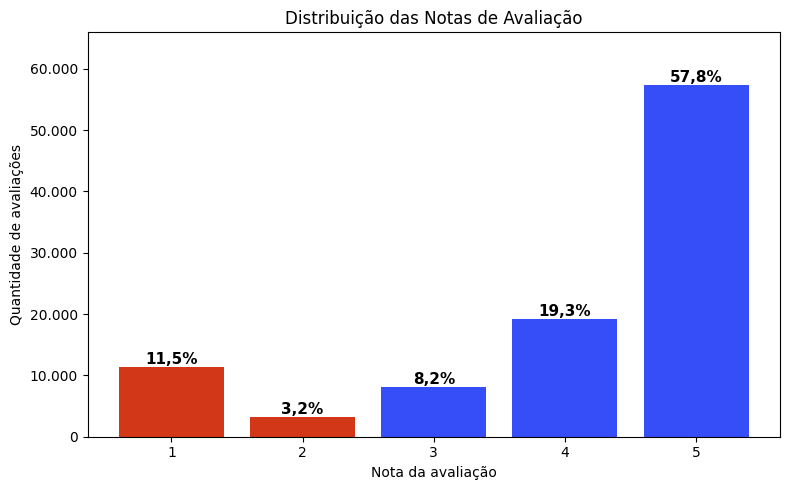

In [7]:
from matplotlib.ticker import FuncFormatter

contagem = reviews["review_score"].value_counts().sort_index()

percentual = contagem / contagem.sum() * 100

cores = [COR_DESTAQUE if nota <= 2 else COR_PRINCIPAL for nota in contagem.index]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(contagem.index, contagem.values, color=cores)

for barra, pct in zip(barras, percentual):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            f"{pct:.1f}%".replace(".", ","), ha="center", va="bottom",
            fontsize=11, fontweight="bold")

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", ".")))
ax.set_ylim(0, contagem.max() * 1.15)
ax.set_xlabel("Nota da avaliação")
ax.set_ylabel("Quantidade de avaliações")
plt.title("Distribuição das Notas de Avaliação")
plt.tight_layout()
plt.savefig("grafico_distribuicao_notas.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura do resultado:** a grande maioria das avaliações é positiva: as notas 4 e 5 somam cerca de 77% do total. As notas 1 e 2 (em vermelho) representam 14,7%. Chama atenção que a nota 1 (11,5%) é bem mais frequente que as notas 2 (3,2%) e 3 (8,2%), o que sugere que, quando o cliente fica insatisfeito, a insatisfação costuma ser forte. Isso leva à próxima pergunta: o que está por trás das notas baixas?

## 2. O atraso na entrega muda a nota?

Cada pedido tem uma data estimada de entrega, prometida ao cliente na hora da compra. Aqui comparamos a data real com a data prometida: se o pedido chegou depois, foi considerado "entregue com atraso". Depois, comparamos a nota média dos dois grupos.

Classificar os pedidos e calcular a nota média.

In [8]:
import numpy as np

avaliacoes["situacao_entrega"] = np.where(
    avaliacoes["order_delivered_customer_date"] > avaliacoes["order_estimated_delivery_date"],
    "Entregue com atraso",
    "Entregue no prazo",
)

resumo_atraso = avaliacoes.groupby("situacao_entrega")["review_score"].agg(["mean", "count"])
resumo_atraso["mean"] = resumo_atraso["mean"].round(2)
print(resumo_atraso)

nota_prazo = resumo_atraso.loc["Entregue no prazo", "mean"]
nota_atraso = resumo_atraso.loc["Entregue com atraso", "mean"]
diferenca = nota_prazo - nota_atraso
print(f"Diferença: {diferenca:.2f} pontos ({diferenca / nota_prazo * 100:.0f}% a menos)")

                     mean  count
situacao_entrega                
Entregue com atraso  2.57   7700
Entregue no prazo    4.29  88639
Diferença: 1.72 pontos (40% a menos)


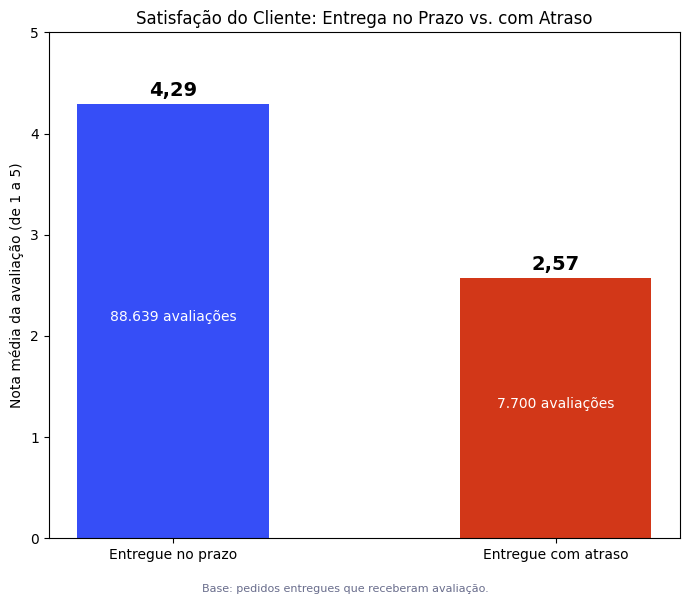

In [9]:
ordem = ["Entregue no prazo", "Entregue com atraso"]
resumo_atraso = resumo_atraso.loc[ordem]
cores = [COR_PRINCIPAL, COR_DESTAQUE]

fig, ax = plt.subplots(figsize=(7, 6))
barras = ax.bar(resumo_atraso.index, resumo_atraso["mean"], color=cores, width=0.5)

for barra, nota, qtd in zip(barras, resumo_atraso["mean"], resumo_atraso["count"]):

    ax.text(barra.get_x() + barra.get_width() / 2, nota + 0.08,
            f"{nota:.2f}".replace(".", ","), ha="center", fontsize=14, fontweight="bold")

    ax.text(barra.get_x() + barra.get_width() / 2, nota / 2,
            f"{qtd:,} avaliações".replace(",", "."), ha="center", color="white", fontsize=10)

ax.set_ylim(0, 5)
ax.set_ylabel("Nota média da avaliação (de 1 a 5)")
plt.title("Satisfação do Cliente: Entrega no Prazo vs. com Atraso")
fig.text(0.5, 0.005, "Base: pedidos entregues que receberam avaliação.",
         ha="center", fontsize=8, color=COR_NEUTRA)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("grafico_nota_atraso.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura do resultado:** pedidos entregues com atraso recebem nota média de 2,57, contra 4,29 dos entregues no prazo. A diferença é de 1,72 ponto, cerca de 40% a menos. Os pedidos atrasados são minoria (cerca de 8% das avaliações), mas pesam de forma desproporcional na percepção do cliente. Trata-se de uma associação observada nos dados: ela não prova, sozinha, que o atraso é a única causa da nota baixa. As próximas análises testam outros fatores para verificar se algum deles tem peso parecido.

## 3. A categoria do produto influencia a nota?

Aqui calculamos a nota média de cada categoria de produto, considerando apenas categorias com pelo menos 100 avaliações, para que uma categoria com poucas avaliações não distorça o resultado. Comparamos as categorias de menor e de maior nota para medir quanto a nota varia de uma para outra.

In [10]:
itens = avaliacoes.merge(order_items, on="order_id", how="inner")

itens = itens.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")

itens = itens.merge(traducao, on="product_category_name", how="left")

itens["categoria"] = (
    itens["product_category_name_english"]
    .fillna(itens["product_category_name"])
    .fillna("sem_categoria")
)

por_categoria = itens.groupby("categoria")["review_score"].agg(["mean", "count"])

por_categoria = por_categoria[por_categoria["count"] >= 100].sort_values("mean")
por_categoria["mean"] = por_categoria["mean"].round(2)

print(len(por_categoria), "categorias com 100 avaliações ou mais")
print()
print("5 menores notas:")
print(por_categoria.head(5))
print()
print("5 maiores notas:")
print(por_categoria.tail(5))

53 categorias com 100 avaliações ou mais

5 menores notas:
                       mean  count
categoria                         
office_furniture       3.52   1664
fashion_male_clothing  3.76    124
fixed_telephony        3.76    253
audio                  3.83    359
home_confort           3.85    430

5 maiores notas:
                        mean  count
categoria                          
fashion_shoes           4.29    256
luggage_accessories     4.35   1073
food_drink              4.37    271
books_technical         4.39    264
books_general_interest  4.51    532


Amplitude entre a melhor e a pior categoria: 0,99 ponto


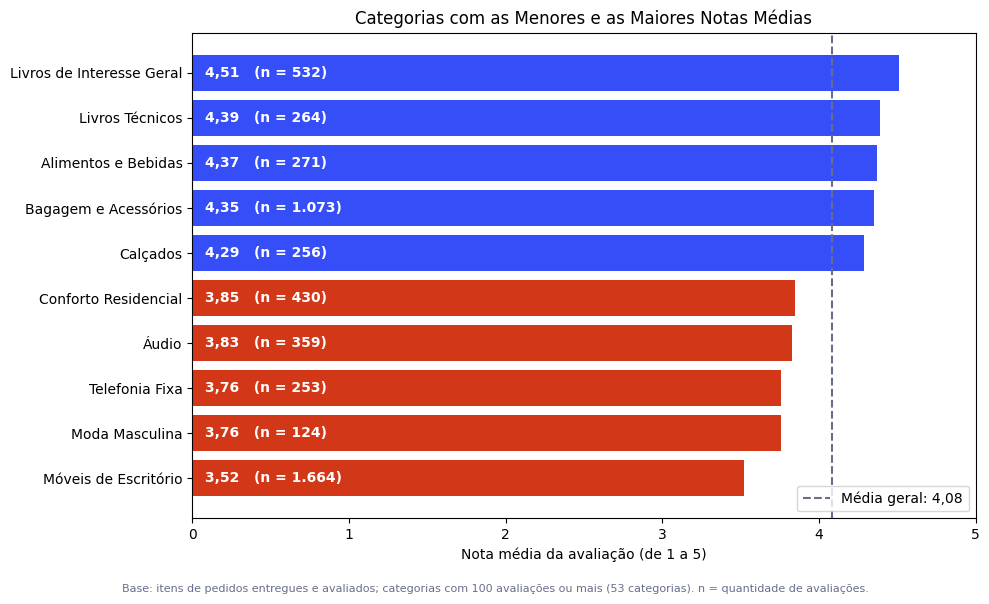

In [11]:
nomes_pt = {
    "office_furniture": "Móveis de Escritório",
    "fashion_male_clothing": "Moda Masculina",
    "fixed_telephony": "Telefonia Fixa",
    "audio": "Áudio",
    "home_confort": "Conforto Residencial",
    "fashion_shoes": "Calçados",
    "luggage_accessories": "Bagagem e Acessórios",
    "food_drink": "Alimentos e Bebidas",
    "books_technical": "Livros Técnicos",
    "books_general_interest": "Livros de Interesse Geral",
}

extremos = pd.concat([por_categoria.head(5), por_categoria.tail(5)]).sort_values("mean")

cores = [COR_DESTAQUE] * 5 + [COR_PRINCIPAL] * 5

media_geral = itens["review_score"].mean()

amplitude = por_categoria["mean"].max() - por_categoria["mean"].min()
print("Amplitude entre a melhor e a pior categoria:", f"{amplitude:.2f}".replace(".", ","), "ponto")

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(extremos.index.map(nomes_pt), extremos["mean"], color=cores)

for barra, nota, n in zip(barras, extremos["mean"], extremos["count"]):
    nota_txt = f"{nota:.2f}".replace(".", ",")
    n_txt = f"{int(n):,}".replace(",", ".")
    ax.text(0.08, barra.get_y() + barra.get_height() / 2,
            f"{nota_txt}   (n = {n_txt})",
            va="center", ha="left", color="white", fontsize=10, fontweight="bold")

media_txt = f"{media_geral:.2f}".replace(".", ",")
ax.axvline(media_geral, color=COR_NEUTRA, linestyle="--", label=f"Média geral: {media_txt}")
ax.legend(loc="lower right")

ax.set_xlim(0, 5)
ax.set_xlabel("Nota média da avaliação (de 1 a 5)")
plt.title("Categorias com as Menores e as Maiores Notas Médias")
fig.text(0.5, 0.005, "Base: itens de pedidos entregues e avaliados; categorias com 100 avaliações ou mais (53 categorias). n = quantidade de avaliações.",
         ha="center", fontsize=8, color=COR_NEUTRA)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("grafico_categorias_nota.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura do resultado:** entre as 53 categorias com pelo menos 100 avaliações, a nota média varia de 3,52 (Móveis de Escritório) a 4,51 (Livros de Interesse Geral), uma diferença de 0,99 ponto. Existe diferença entre as categorias, mas ela é menor que a observada entre pedidos atrasados e entregues no prazo (1,72 ponto). Há uma ressalva: as categorias também podem diferir em prazo de entrega e em outras características, então a diferença não deve ser lida, necessariamente, como efeito da categoria em si.

## 4. Quem escreve comentário avalia diferente de quem não escreve?

Além da nota, o cliente pode deixar um comentário em texto. Aqui comparamos a nota média de quem comentou com a de quem não comentou. Diferente das análises anteriores, esta considera todas as avaliações da base, independentemente do status do pedido.

In [12]:
comentarios = reviews.copy()

comentarios["tem_comentario"] = comentarios["review_comment_message"].fillna("").str.strip() != ""

comentarios["tipo_review"] = np.where(comentarios["tem_comentario"], "Com comentário", "Sem comentário")

resumo_comentario = comentarios.groupby("tipo_review")["review_score"].agg(["mean", "count"])
resumo_comentario["mean"] = resumo_comentario["mean"].round(2)
print(resumo_comentario)

pct_por_nota = comentarios.groupby("review_score")["tem_comentario"].mean() * 100
print()
print("% de avaliações com comentário, por nota:")
print(pct_por_nota.round(1))

                mean  count
tipo_review                
Com comentário  3.67  40950
Sem comentário  4.38  58274

% de avaliações com comentário, por nota:
review_score
1    76.5
2    68.1
3    43.5
4    31.2
5    35.8
Name: tem_comentario, dtype: float64


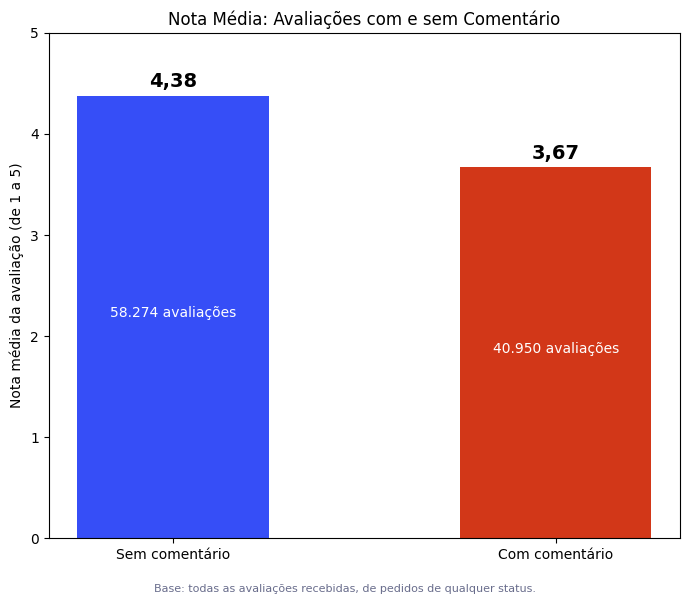

In [13]:
ordem = ["Sem comentário", "Com comentário"]
resumo_comentario = resumo_comentario.loc[ordem]
cores = [COR_PRINCIPAL, COR_DESTAQUE]

fig, ax = plt.subplots(figsize=(7, 6))
barras = ax.bar(resumo_comentario.index, resumo_comentario["mean"], color=cores, width=0.5)

for barra, nota, qtd in zip(barras, resumo_comentario["mean"], resumo_comentario["count"]):
    ax.text(barra.get_x() + barra.get_width() / 2, nota + 0.08,
            f"{nota:.2f}".replace(".", ","), ha="center", fontsize=14, fontweight="bold")
    ax.text(barra.get_x() + barra.get_width() / 2, nota / 2,
            f"{qtd:,} avaliações".replace(",", "."), ha="center", color="white", fontsize=10)

ax.set_ylim(0, 5)
ax.set_ylabel("Nota média da avaliação (de 1 a 5)")
plt.title("Nota Média: Avaliações com e sem Comentário")
fig.text(0.5, 0.005, "Base: todas as avaliações recebidas, de pedidos de qualquer status.",
         ha="center", fontsize=8, color=COR_NEUTRA)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("grafico_nota_comentario.png", dpi=200, bbox_inches="tight")
plt.show()

### Gráfico do percentual de comentários por nota

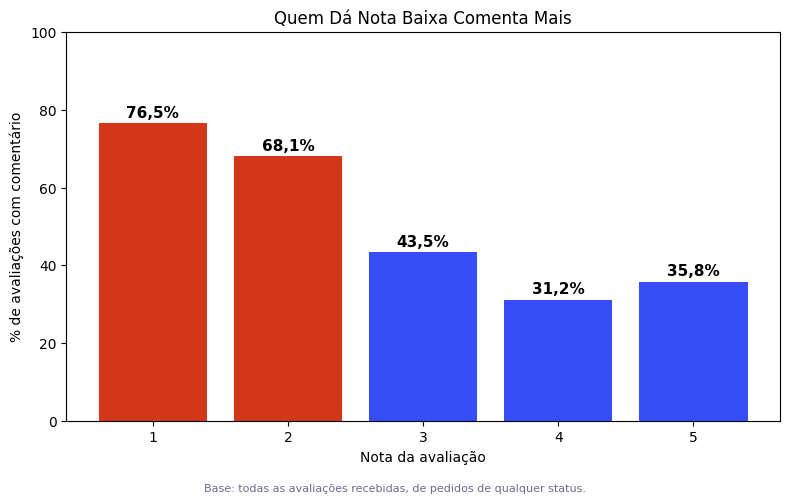

In [14]:
cores = [COR_DESTAQUE if nota <= 2 else COR_PRINCIPAL for nota in pct_por_nota.index]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(pct_por_nota.index, pct_por_nota.values, color=cores)

for barra, pct in zip(barras, pct_por_nota.values):
    ax.text(barra.get_x() + barra.get_width() / 2, pct + 1.5,
            f"{pct:.1f}%".replace(".", ","), ha="center", fontsize=11, fontweight="bold")

ax.set_ylim(0, 100)
ax.set_xlabel("Nota da avaliação")
ax.set_ylabel("% de avaliações com comentário")
plt.title("Quem Dá Nota Baixa Comenta Mais")
fig.text(0.5, 0.005, "Base: todas as avaliações recebidas, de pedidos de qualquer status.",
         ha="center", fontsize=8, color=COR_NEUTRA)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("grafico_comentario_por_nota.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura do resultado:** clientes que escrevem comentário dão nota média de 3,67, contra 4,38 de quem não comenta. O gráfico acima ajuda a entender o motivo: entre as avaliações com nota 1, 76,5% trazem comentário; entre as de nota 5, são 35,8%. Isso é coerente com a ideia de que clientes insatisfeitos têm mais motivação para escrever, o que puxa para baixo a média do grupo "com comentário". Ou seja, a diferença reflete quem costuma comentar, e não um efeito do comentário sobre a nota. Por isso, a ausência de comentário não deve ser lida como neutra, e os textos dos comentários são uma fonte útil para investigar os motivos da insatisfação em análises futuras.

## 5. O tempo de aprovação do pedido influencia a nota?

Depois da compra, o pedido passa por uma aprovação. Aqui medimos quantas horas se passaram entre a compra e a aprovação, separamos os pedidos em três faixas (até 1 hora, de 1 a 24 horas e mais de 24 horas) e comparamos a nota média de cada faixa.

In [15]:
avaliacoes["horas_ate_aprovacao"] = (
    avaliacoes["order_approved_at"] - avaliacoes["order_purchase_timestamp"]
).dt.total_seconds() / 3600

avaliacoes["faixa_aprovacao"] = pd.cut(
    avaliacoes["horas_ate_aprovacao"],
    bins=[-float("inf"), 1, 24, float("inf")],
    labels=["Até 1 hora", "De 1 a 24 horas", "Mais de 24 horas"],
)

resumo_aprovacao = avaliacoes.groupby("faixa_aprovacao", observed=True)["review_score"].agg(["mean", "count"])
resumo_aprovacao["mean"] = resumo_aprovacao["mean"].round(2)
print(resumo_aprovacao)

diferenca = resumo_aprovacao["mean"].max() - resumo_aprovacao["mean"].min()
print("Diferença entre a maior e a menor nota média:", f"{diferenca:.2f}".replace(".", ","), "ponto")

                  mean  count
faixa_aprovacao              
Até 1 hora        4.17  61625
De 1 a 24 horas   4.16  17828
Mais de 24 horas  4.11  16886
Diferença entre a maior e a menor nota média: 0,06 ponto


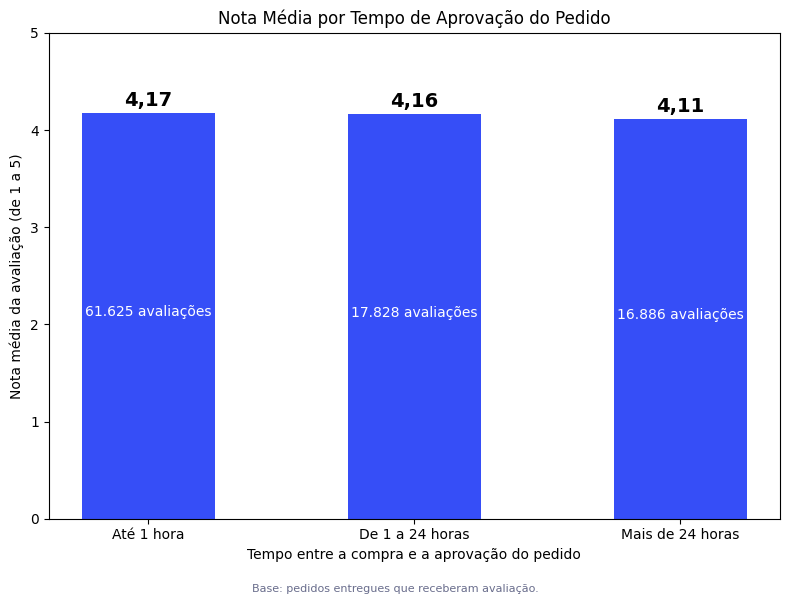

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.bar(resumo_aprovacao.index.astype(str), resumo_aprovacao["mean"], color=COR_PRINCIPAL, width=0.5)

for barra, nota, qtd in zip(barras, resumo_aprovacao["mean"], resumo_aprovacao["count"]):
    ax.text(barra.get_x() + barra.get_width() / 2, nota + 0.08,
            f"{nota:.2f}".replace(".", ","), ha="center", fontsize=14, fontweight="bold")
    ax.text(barra.get_x() + barra.get_width() / 2, nota / 2,
            f"{qtd:,} avaliações".replace(",", "."), ha="center", color="white", fontsize=10)

ax.set_ylim(0, 5)
ax.set_xlabel("Tempo entre a compra e a aprovação do pedido")
ax.set_ylabel("Nota média da avaliação (de 1 a 5)")
plt.title("Nota Média por Tempo de Aprovação do Pedido")
fig.text(0.5, 0.005, "Base: pedidos entregues que receberam avaliação.",
         ha="center", fontsize=8, color=COR_NEUTRA)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("grafico_nota_aprovacao.png", dpi=200, bbox_inches="tight")
plt.show()

**Leitura do resultado:** a nota média praticamente não muda com o tempo de aprovação: 4,17 para pedidos aprovados em até 1 hora, 4,16 para os de 1 a 24 horas e 4,11 para os de mais de 24 horas, uma diferença de apenas 0,06 ponto. A maior parte dos pedidos (cerca de 64%) é aprovada em até 1 hora. Entre os fatores analisados até aqui, o tempo de aprovação é o que menos se associa à nota do cliente.